## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

np.random.seed(42)
sns.set_style('whitegrid')

## 3. Load the Data

In [2]:
data = pd.read_csv('Hospital_Operations_Dataset.csv')
print("Shape:", data.shape)
data.head()

Shape: (100000, 15)


,Patient_ID,Age,Gender,Department,Diagnosis,Severity_Level,Admission_Date,Discharge_Date,Length_of_Stay_Days,Wait_Time_Minutes,Doctor_ID,Insurance_Type,Treatment_Cost_USD,Readmission_Flag,Outcome
0,PAT000001,23.0,NaN,Gynecology,Cancer,Low,2026-05-02 06:06:47.667330,2026-05-04 06:06:47.667330,2.0,79.0,DOC0350,Employer,485,0,Recovered
1,PAT000002,48.0,Male,Neurology,Kidney Disease,Medium,2026-03-24 15:52:16.633920,2026-03-30 15:52:16.633920,NaN,167.0,DOC0267,Private,3487,0,Improved
2,PAT000003,63.0,Male,Neurology,Stroke,Low,2025-09-07 03:51:37.073134,2025-09-10 03:51:37.073134,3.0,281.0,DOC0197,Self-Pay,716,0,Recovered
3,PAT000004,85.0,Male,Emergency,Asthma,Medium,2024-11-19 00:17:09.630895,2024-11-21 00:17:09.630895,2.0,271.0,DOC0009,Government,2111,0,Recovered
4,PAT000005,93.0,Female,Neurology,Pneumonia,Medium,2024-07-20 04:48:22.195440,2024-07-27 04:48:22.195440,7.0,NaN,DOC0219,Self-Pay,4968,0,NaN


## 4. Checking Data Quality First

In [3]:
print("Missing values per column:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print("\nDuplicate rows:", data.duplicated().sum())

Missing values per column:
Age                    4000
Gender                 2000
Department             3000
Diagnosis              3000
Severity_Level         5000
Length_of_Stay_Days    4000
Wait_Time_Minutes      6000
Insurance_Type         3000
Outcome                2000
dtype: int64

Duplicate rows: 0


In [4]:
cols_to_check = ['Age', 'Length_of_Stay_Days', 'Wait_Time_Minutes', 'Treatment_Cost_USD']
data[cols_to_check].describe()

,Age,Length_of_Stay_Days,Wait_Time_Minutes,Treatment_Cost_USD
count,96000.000000,96000.000000,94000.000000,100000.000000
mean,47.750094,6.346135,161.785574,4893.894900
std,28.389922,17.008076,163.352006,7710.109305
min,0.000000,1.000000,5.000000,100.000000
25%,23.000000,2.000000,78.000000,662.000000
50%,48.000000,3.000000,153.000000,2142.000000
75%,72.000000,7.000000,228.000000,5002.250000
max,199.000000,398.000000,2997.000000,49999.000000


In [5]:
neg_counts = (data[cols_to_check] < 0).sum()
neg_counts

,0
Age,0
Length_of_Stay_Days,0
Wait_Time_Minutes,0
Treatment_Cost_USD,0


## 5. Cleaning: Nulls and Invalid Values



In [6]:
domain_bounds = {
    'Age': (1, 100),
    'Length_of_Stay_Days': (1, 35),
    'Wait_Time_Minutes': (0, 300),
    'Treatment_Cost_USD': (1, 50000),
}

invalid_counts = {}
for col, (lo, hi) in domain_bounds.items():
    invalid = ((data[col] < lo) | (data[col] > hi)) & data[col].notna()
    invalid_counts[col] = int(invalid.sum())
    data.loc[invalid, col] = np.nan

pd.Series(invalid_counts)

# Split the cleaned bulk dataset once into train.csv and test.csv
train_data, test_data = train_test_split(
    data,
    test_size=0.20,
    random_state=42
)

train_data.to_csv('train.csv', index=False)
test_data.to_csv('test.csv', index=False)

print("Train CSV:", train_data.shape)
print("Test CSV:", test_data.shape)


Train CSV: (80000, 15)
Test CSV: (20000, 15)


In [7]:
data[list(domain_bounds)].isnull().sum()

,0
Age,5291
Length_of_Stay_Days,4400
Wait_Time_Minutes,6500
Treatment_Cost_USD,0


Missing values (the original nulls and the invalid values we just turned into nulls) are **not** filled here.
They are filled with `SimpleImputer` after the train/test split (Section 9), using the training data only, so no information from the test set leaks into the training data.

In [8]:
data[cols_to_check].describe()

,Age,Length_of_Stay_Days,Wait_Time_Minutes,Treatment_Cost_USD
count,94709.000000,95600.000000,93500.000000,100000.000000
mean,47.903515,5.358483,152.125316,4893.894900
std,27.451010,4.968706,85.528181,7710.109305
min,1.000000,1.000000,5.000000,100.000000
25%,24.000000,2.000000,78.000000,662.000000
50%,48.000000,3.000000,152.000000,2142.000000
75%,72.000000,7.000000,226.000000,5002.250000
max,95.000000,30.000000,300.000000,49999.000000


In [9]:
(data[cols_to_check] <= 0).sum()

,0
Age,0
Length_of_Stay_Days,0
Wait_Time_Minutes,0
Treatment_Cost_USD,0


## 6. Exploratory Data Analysis

### Categorical Columns

In [10]:
categorical_cols = ['Gender', 'Department', 'Diagnosis', 'Severity_Level', 'Insurance_Type', 'Outcome']
data[categorical_cols].nunique()

,0
Gender,2
Department,10
Diagnosis,10
Severity_Level,4
Insurance_Type,4
Outcome,4


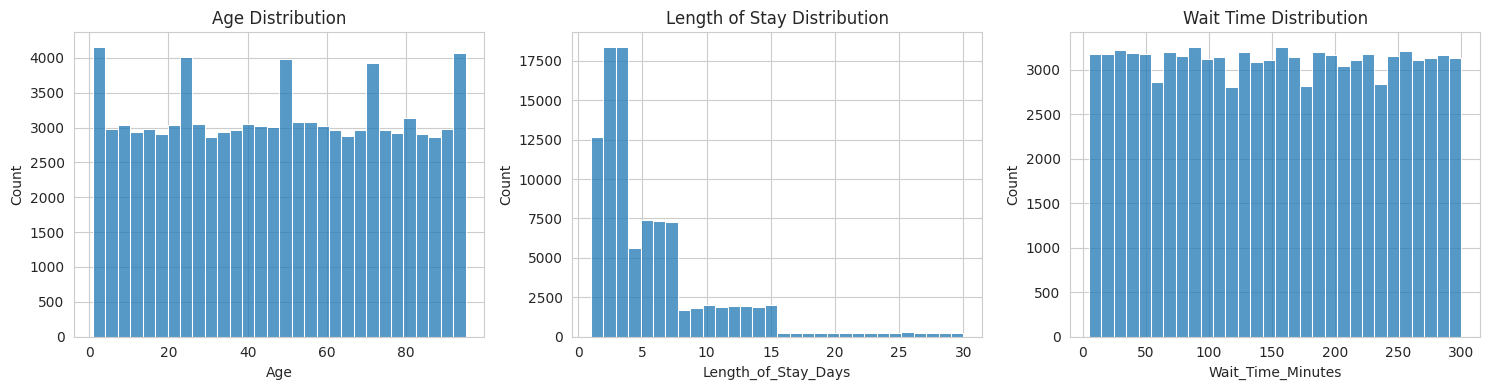

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data['Age'], bins=30, ax=axes[0]); axes[0].set_title('Age Distribution')
sns.histplot(data['Length_of_Stay_Days'], bins=30, ax=axes[1]); axes[1].set_title('Length of Stay Distribution')
sns.histplot(data['Wait_Time_Minutes'], bins=30, ax=axes[2]); axes[2].set_title('Wait Time Distribution')
plt.tight_layout()
plt.show()

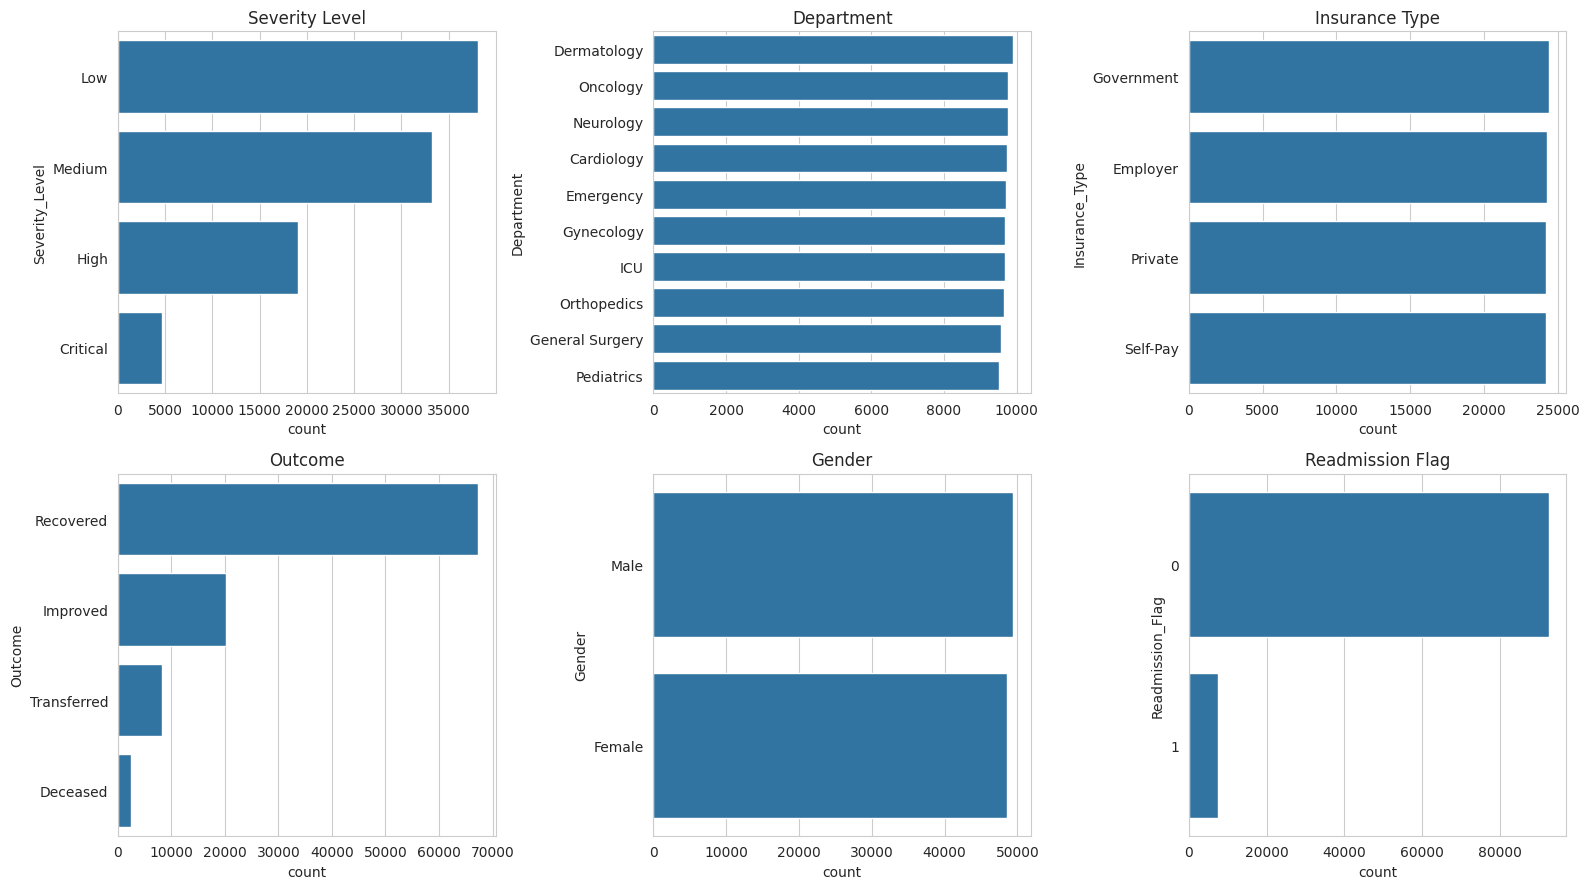

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(y='Severity_Level', data=data, order=['Low', 'Medium', 'High', 'Critical'], ax=axes[0, 0]); axes[0, 0].set_title('Severity Level')
sns.countplot(y='Department', data=data, order=data['Department'].value_counts().index, ax=axes[0, 1]); axes[0, 1].set_title('Department')
sns.countplot(y='Insurance_Type', data=data, order=data['Insurance_Type'].value_counts().index, ax=axes[0, 2]); axes[0, 2].set_title('Insurance Type')
sns.countplot(y='Outcome', data=data, order=data['Outcome'].value_counts().index, ax=axes[1, 0]); axes[1, 0].set_title('Outcome')
sns.countplot(y='Gender', data=data, ax=axes[1, 1]); axes[1, 1].set_title('Gender')
sns.countplot(y='Readmission_Flag', data=data, ax=axes[1, 2]); axes[1, 2].set_title('Readmission Flag')
plt.tight_layout()
plt.show()



### Distribution of the Target

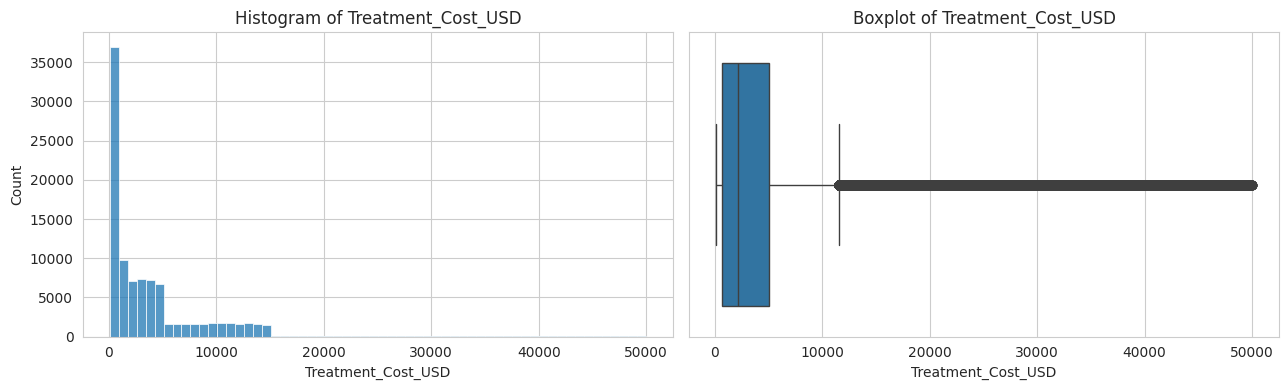

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data['Treatment_Cost_USD'], bins=60, ax=axes[0])
axes[0].set_title('Histogram of Treatment_Cost_USD')
sns.boxplot(x=data['Treatment_Cost_USD'], ax=axes[1])
axes[1].set_title('Boxplot of Treatment_Cost_USD')
plt.tight_layout()
plt.show()



### Cost vs. the Numeric Features

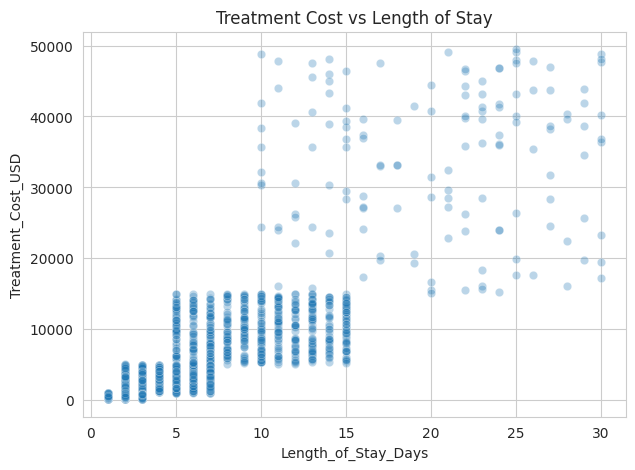

In [14]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='Length_of_Stay_Days', y='Treatment_Cost_USD',
                 data=data.sample(3000, random_state=42), alpha=0.3)
plt.title('Treatment Cost vs Length of Stay')
plt.show()

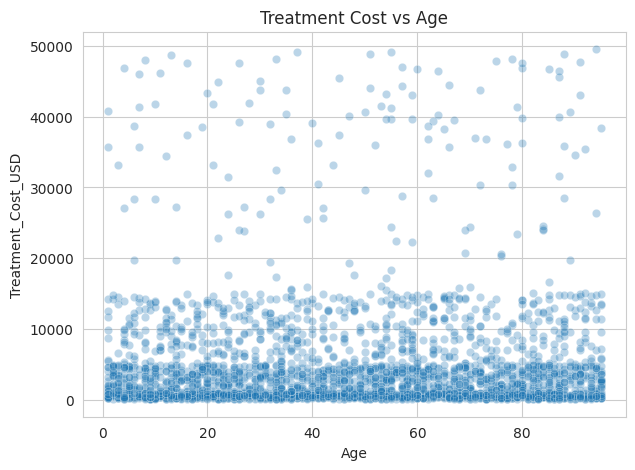

In [15]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='Age', y='Treatment_Cost_USD',
                 data=data.sample(3000, random_state=42), alpha=0.3)
plt.title('Treatment Cost vs Age')
plt.show()


### Cost by Severity, Department, Insurance, Outcome, Readmission

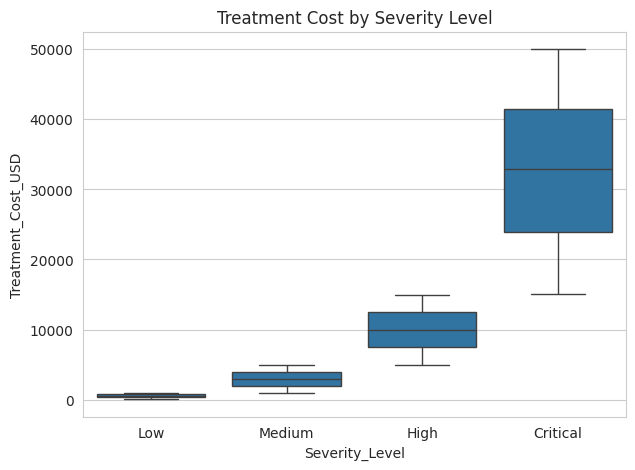

In [16]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='Severity_Level', y='Treatment_Cost_USD', data=data,
            order=['Low', 'Medium', 'High', 'Critical'])
plt.title('Treatment Cost by Severity Level')
plt.show()

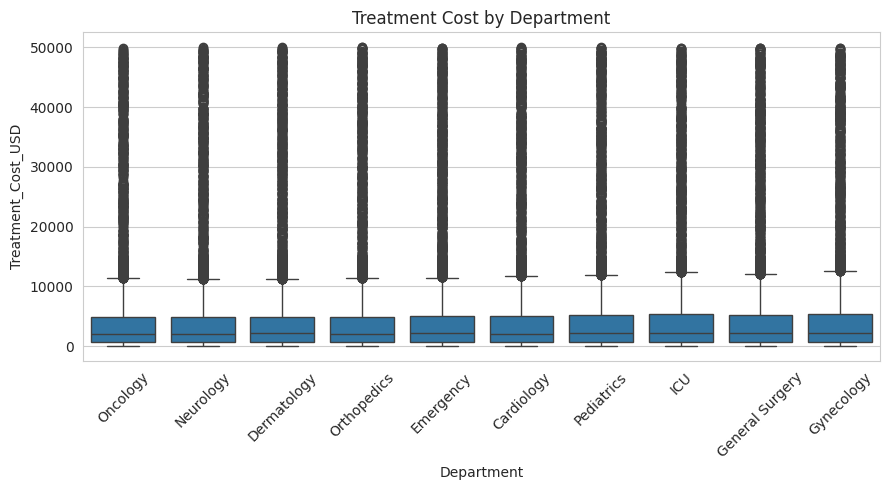

In [17]:
dept_order = data.groupby('Department')['Treatment_Cost_USD'].mean().sort_values().index
plt.figure(figsize=(9, 5))
sns.boxplot(x='Department', y='Treatment_Cost_USD', data=data, order=dept_order)
plt.xticks(rotation=45)
plt.title('Treatment Cost by Department')
plt.tight_layout()
plt.show()

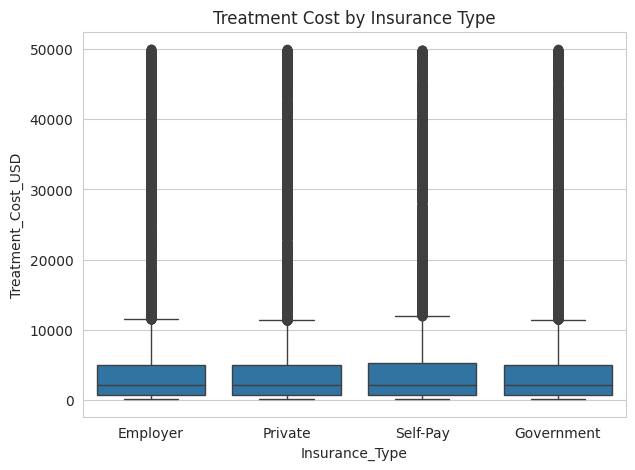

In [18]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='Insurance_Type', y='Treatment_Cost_USD', data=data)
plt.title('Treatment Cost by Insurance Type')
plt.show()

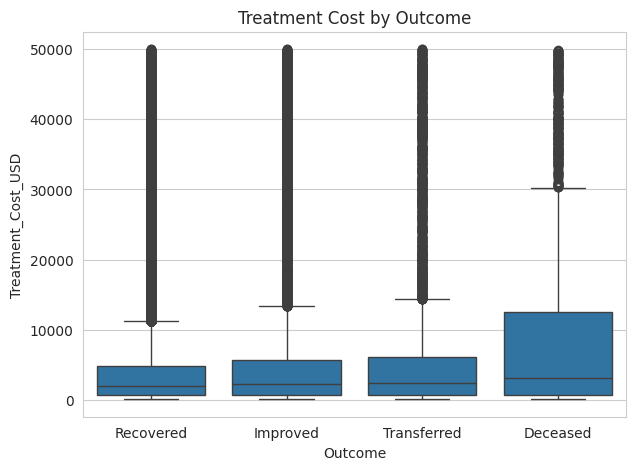

In [19]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='Outcome', y='Treatment_Cost_USD', data=data)
plt.title('Treatment Cost by Outcome')
plt.show()

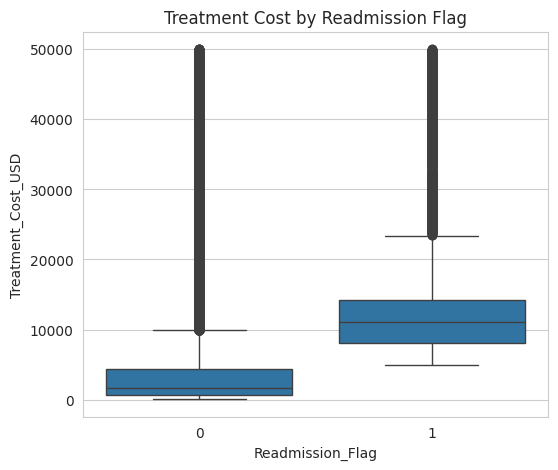

In [20]:
plt.figure(figsize=(6, 5))
sns.boxplot(x='Readmission_Flag', y='Treatment_Cost_USD', data=data)
plt.title('Treatment Cost by Readmission Flag')
plt.show()



### Correlation with the Target

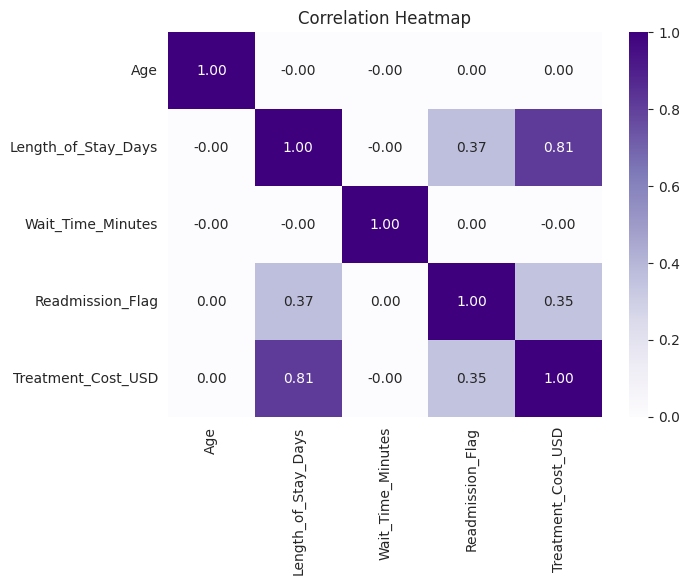

In [21]:
numeric_check_cols = ['Age', 'Length_of_Stay_Days', 'Wait_Time_Minutes', 'Readmission_Flag', 'Treatment_Cost_USD']
plt.figure(figsize=(7, 5))
sns.heatmap(data[numeric_check_cols].corr(), annot=True, fmt='.2f', cmap='Purples')
plt.title('Correlation Heatmap')
plt.show()

## 7. Feature Selection



In [22]:
dates_check = data.copy()
date_cols = ['Admission_Date', 'Discharge_Date']
dates_check[date_cols] = dates_check[date_cols].apply(pd.to_datetime)
dates_check['stay_from_dates'] = (dates_check['Discharge_Date'] - dates_check['Admission_Date']).dt.days

# compare only the rows where Length_of_Stay_Days is not missing
has_stay = dates_check['Length_of_Stay_Days'].notna()
mismatches = (dates_check.loc[has_stay, 'stay_from_dates'] != dates_check.loc[has_stay, 'Length_of_Stay_Days']).sum()
print("Rows where (Discharge_Date - Admission_Date) != Length_of_Stay_Days:", mismatches)

Rows where (Discharge_Date - Admission_Date) != Length_of_Stay_Days: 0


## 8. Preprocessing


The data is split **first**. Imputers, encoders and scalers are fitted later on the training set only.

In [23]:
# Use the saved training split only
train_data = pd.read_csv('train.csv')

model_data = train_data.drop(columns=['Patient_ID', 'Doctor_ID', 'Admission_Date', 'Discharge_Date'])

target_column = 'Treatment_Cost_USD'
X_train = model_data.drop(columns=[target_column])
y_train = model_data[target_column]

input_columns = list(X_train.columns)   # original column order (needed for new patients later)

print("Train:", X_train.shape)


Train: (80000, 10)


## 9. Imputation, Encoding and Scaling

### Missing Values (SimpleImputer)

In [24]:
numeric_cols = ['Age', 'Length_of_Stay_Days', 'Wait_Time_Minutes']
# categorical_cols was defined in the EDA section

numeric_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')

# fit on the training set only, then transform the training set
X_train[numeric_cols] = numeric_imputer.fit_transform(X_train[numeric_cols])
X_train[categorical_cols] = categorical_imputer.fit_transform(X_train[categorical_cols])

print("Nulls left in train:", X_train.isnull().sum().sum())


Nulls left in train: 0


### Encoding

In [25]:
# Severity_Level has a meaningful order -> OrdinalEncoder
severity_encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Critical']])
X_train[['Severity_Level']] = severity_encoder.fit_transform(X_train[['Severity_Level']])

# Gender has only two categories -> label encoding
gender_encoder = LabelEncoder()
X_train['Gender'] = gender_encoder.fit_transform(X_train['Gender'])

# the other categorical columns have more than two categories -> OneHotEncoder
nominal_cols = ['Department', 'Diagnosis', 'Insurance_Type', 'Outcome']
onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)

train_onehot = pd.DataFrame(
    onehot_encoder.fit_transform(X_train[nominal_cols]),
    columns=onehot_encoder.get_feature_names_out(nominal_cols),
    index=X_train.index
)

X_train = pd.concat([X_train.drop(columns=nominal_cols), train_onehot], axis=1)

feature_columns = list(X_train.columns)
print("Number of features after encoding:", len(feature_columns))


Number of features after encoding: 30


### Scaling

In [26]:
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

X_train[numeric_cols].head()


,Age,Length_of_Stay_Days,Wait_Time_Minutes
0,-1.305095,-0.666457,-1.436837
1,0.227256,-0.666457,0.304185
2,-0.707104,0.356744,1.513228
3,-0.744479,-0.666457,1.779217
4,-1.566715,-0.666457,1.053792


In [27]:
target_scaler = StandardScaler()
y_train_scaled = pd.Series(
    target_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel(),
    index=y_train.index
)

## 10. Train the Models



In [28]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr_train = lr.predict(X_train)


In [29]:
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
pred_dt_train = dt.predict(X_train)


In [30]:
svr_sample_size = 10000
svr_idx = X_train.sample(svr_sample_size, random_state=42).index

X_train_svr = X_train.loc[svr_idx]
y_train_svr_scaled = y_train_scaled.loc[svr_idx]

svr = SVR(kernel='rbf', C=10)
svr.fit(X_train_svr, y_train_svr_scaled)

# training predictions: on the 10,000 rows the SVR was trained on
pred_svr_train_scaled = svr.predict(X_train_svr)
pred_svr_train = target_scaler.inverse_transform(
    pred_svr_train_scaled.reshape(-1, 1)
).ravel()


### Random Forest (a more complex model)

In [31]:
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf_train = rf.predict(X_train)

print("All models trained.")


All models trained.


## 11. Evaluation


In [32]:
train_predictions = {
    'Linear Regression': pred_lr_train,
    'Decision Tree Regressor': pred_dt_train,
    'Support Vector Regressor (RBF)': pred_svr_train,
    'Random Forest Regressor': pred_rf_train,
}

# the actual training values for each model (the SVR was trained on a 10,000-row sample)
train_actual = {name: y_train for name in train_predictions}
train_actual['Support Vector Regressor (RBF)'] = y_train.loc[svr_idx]

results = []
for name, pred_tr in train_predictions.items():
    y_tr = train_actual[name]
    results.append({
        'Model': name,
        'Train_MAE': mean_absolute_error(y_tr, pred_tr),
        'Train_MSE': mean_squared_error(y_tr, pred_tr),
        'Train_R2': r2_score(y_tr, pred_tr),
    })

results_df = pd.DataFrame(results)
results_df.round({'Train_MAE': 2, 'Train_MSE': 2, 'Train_R2': 4})


,Model,Train_MAE,Train_MSE,Train_R2
0,Linear Regression,2475.75,18714822.43,0.6859
1,Decision Tree Regressor,1325.56,6746902.93,0.8868
2,Support Vector Regressor (RBF),764.32,1553158.24,0.9734
3,Random Forest Regressor,1310.12,6072056.83,0.8981


In [33]:
# Compare the training scores of the models
original_models = results_df[results_df['Model'] != 'Random Forest Regressor']
best_original = original_models.sort_values('Train_R2', ascending=False).iloc[0]
rf_result = results_df[results_df['Model'] == 'Random Forest Regressor'].iloc[0]

print("Best of the original models:", best_original['Model'], "- Train R2 =", round(best_original['Train_R2'], 4))
print("Random Forest Regressor:    ", "Train R2 =", round(rf_result['Train_R2'], 4))


Best of the original models: Support Vector Regressor (RBF) - Train R2 = 0.9734
Random Forest Regressor:     Train R2 = 0.8981


In [34]:
# Training-only results are shown here because the final test set is kept
# completely separate and is evaluated in test.ipynb.
results_df[['Model', 'Train_R2']].round(4)


,Model,Train_R2
0,Linear Regression,0.6859
1,Decision Tree Regressor,0.8868
2,Support Vector Regressor (RBF),0.9734
3,Random Forest Regressor,0.8981


### Training vs Testing Performance

### Training Performance

The models were trained using the training dataset only.

The final model used for the project is the Random Forest Regressor. The test dataset is kept completely unseen during training and model selection.

The final performance on the unseen test dataset is reported separately in `test_PR.ipynb`.

## 12. Picking a Model



In [35]:
fitted_models = {
    'Linear Regression': lr,
    'Decision Tree Regressor': dt,
    'Support Vector Regressor (RBF)': svr,
    'Random Forest Regressor': rf
}

# Keep the final test set completely unseen during training/model selection.
# Random Forest is the predefined final model used by the project.
best_name = 'Random Forest Regressor'
final_model = fitted_models[best_name]
final_predictions = train_predictions[best_name]

final_mae = mean_absolute_error(y_train, final_predictions)
final_mse = mean_squared_error(y_train, final_predictions)
final_r2 = r2_score(y_train, final_predictions)

print("Final model:", best_name)
print("Training MAE:", f"{final_mae:,.2f}")
print("Training MSE:", f"{final_mse:,.2f}")
print("Training R2: ", f"{final_r2:.4f}")


Final model: Random Forest Regressor
Training MAE: 1,310.12
Training MSE: 6,072,056.83
Training R2:  0.8981


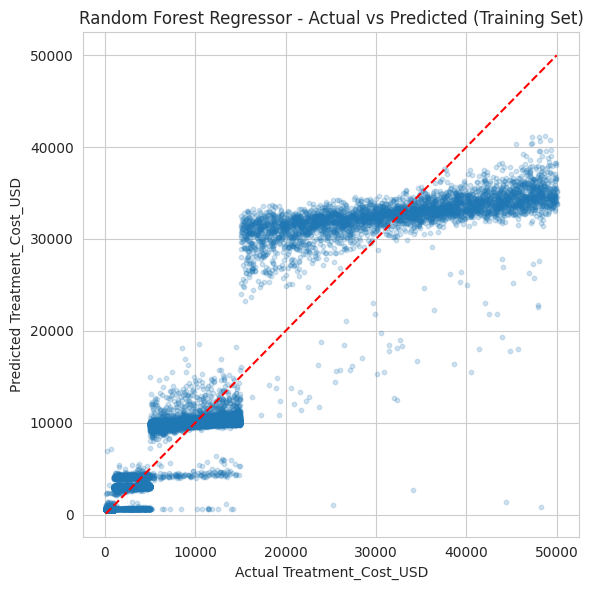

In [36]:
plt.figure(figsize=(6, 6))
plt.scatter(y_train, final_predictions, alpha=0.2, s=10)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color='red', linestyle='--')
plt.xlabel('Actual Treatment_Cost_USD')
plt.ylabel('Predicted Treatment_Cost_USD')
plt.title(f'{best_name} - Actual vs Predicted (Training Set)')
plt.tight_layout()
plt.show()


## 13. Save the Model



In [37]:
model_bundle = {
    'model': final_model,
    'model_name': best_name,
    'numeric_imputer': numeric_imputer,
    'categorical_imputer': categorical_imputer,
    'severity_encoder': severity_encoder,
    'gender_encoder': gender_encoder,
    'onehot_encoder': onehot_encoder,
    'scaler': scaler,
    'target_scaler': target_scaler if best_name == 'Support Vector Regressor (RBF)' else None,
    'uses_target_scaling': best_name == 'Support Vector Regressor (RBF)',
    'numeric_cols': numeric_cols,
    'categorical_cols': categorical_cols,
    'nominal_cols': nominal_cols,
    'input_columns': input_columns,
    'feature_columns': feature_columns,
    'domain_bounds': domain_bounds,
    'test_size': 0.20,
    'random_state': 42,
    'train_metrics': {'MAE': final_mae, 'MSE': final_mse, 'R2': final_r2},
}

joblib.dump(model_bundle, 'model_file.joblib')
print("Saved: model_file.joblib")


Saved: model_file.joblib


## 14. Load and Verify the Saved Model


In [38]:
loaded_bundle = joblib.load('model_file.joblib')
loaded_model = loaded_bundle['model']

# start from the raw training data and apply the SAVED imputers / encoders / scaler (transform only)
X_verify_train = train_data.drop(
    columns=['Patient_ID', 'Doctor_ID', 'Admission_Date', 'Discharge_Date', target_column]
).copy()
y_verify_train = y_train.copy()

num_cols = loaded_bundle['numeric_cols']
cat_cols = loaded_bundle['categorical_cols']
nom_cols = loaded_bundle['nominal_cols']

X_verify_train[num_cols] = loaded_bundle['numeric_imputer'].transform(X_verify_train[num_cols])
X_verify_train[cat_cols] = loaded_bundle['categorical_imputer'].transform(X_verify_train[cat_cols])

X_verify_train[['Severity_Level']] = loaded_bundle['severity_encoder'].transform(
    X_verify_train[['Severity_Level']]
)
X_verify_train['Gender'] = loaded_bundle['gender_encoder'].transform(
    X_verify_train['Gender']
)

onehot_loaded = loaded_bundle['onehot_encoder']
verify_onehot = pd.DataFrame(
    onehot_loaded.transform(X_verify_train[nom_cols]),
    columns=onehot_loaded.get_feature_names_out(nom_cols),
    index=X_verify_train.index
)
X_verify_train = pd.concat(
    [X_verify_train.drop(columns=nom_cols), verify_onehot],
    axis=1
)

X_verify_train[num_cols] = loaded_bundle['scaler'].transform(X_verify_train[num_cols])
X_verify_train = X_verify_train[loaded_bundle['feature_columns']]

verify_predictions = loaded_model.predict(X_verify_train)
if loaded_bundle['uses_target_scaling']:
    verify_predictions = loaded_bundle['target_scaler'].inverse_transform(
        verify_predictions.reshape(-1, 1)
    ).ravel()

verify_mae = mean_absolute_error(y_verify_train, verify_predictions)
verify_r2 = r2_score(y_verify_train, verify_predictions)

print("Reloaded model training MAE:", f"{verify_mae:,.2f}")
print("Reloaded model training R2: ", f"{verify_r2:.4f}")
print(
    "\nMatches original training evaluation:",
    np.isclose(verify_mae, final_mae) and np.isclose(verify_r2, final_r2)
)


Reloaded model training MAE: 1,310.12
Reloaded model training R2:  0.8981

Matches original training evaluation: True


In [39]:
preview = train_data.copy()
preview['Predicted_Treatment_Cost_USD'] = verify_predictions.round(1)
preview['Actual_Treatment_Cost_USD'] = y_verify_train.values
preview[['Predicted_Treatment_Cost_USD', 'Actual_Treatment_Cost_USD']].head(10)


,Predicted_Treatment_Cost_USD,Actual_Treatment_Cost_USD
0,612.8,765.0
1,3028.8,3778.0
2,2968.0,2615.0
3,633.4,287.0
4,616.7,698.0
5,631.4,342.0
6,9886.2,5213.0
7,620.5,764.0
8,9851.5,8823.0
9,3054.6,2665.0


In [40]:
!pip install streamlit -q
!streamlit run app.py &>/content/logs.txt &
!curl ipv4.icanhazip.com
!npx localtunnel --port 8501

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 75.8 MB/s eta 0:00:00
8.228.104.72
⠙⠹⠸⠼⠴⠦⠧⠇⠏Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) n

⠙npm error canceled
⠙npm error A complete log of this run can be found in: /root/.npm/_logs/2026-09-30T23_16_06_725Z-debug-0.log
⠙